# 06 · Approaches from the course methods, for tasks (a) and (c)

The checkpoint feedback asked for more interesting approaches, built with the methods of the course, and for every choice to be justified. This notebook tries, for **(a)** the conference ranking and **(c)** penalty minutes:

| Approach | Course topic | Task | The idea in one line |
|---|---|---|---|
| Pairwise ranking | T03 Classification | (a) | A ranking is about order, so learn "does team A finish above team B?" |
| Voting ensemble | T05 Ensembles | (a) | Models that learn differently make different mistakes; averaging can cancel some |
| Team-style clusters as an input | T07 Clustering | (a) | Teams of the same "style" may move the same way from one season to the next |
| Recent seasons count more | Data streams / online learning | (a), (c) | The game changes over time, so old seasons may be less relevant |
| Rate × games | T02 Regression | (c) | Split the total into two parts: penalties per game, and games played |
| Two-step model | T03 + T02 | (c) | 12% of players get 0: first "any penalties?", then "how many?" |
| Stacking | T05 Ensembles | (c) | Learn how much to trust each model, from the practice seasons |

**How everything is compared:** the same test as notebooks 03–05 (9 test seasons 2000–2009, each predicted only from earlier seasons). Every setting (number of clusters, weight of recent seasons) is chosen by the **practice test** (the last 3 training seasons), never by looking at the test seasons. Each approach is compared with:
- the **best rule with no learning** (a: Pythagorean expectation 3.16; c: Marcel 17.17), and
- **our best model so far** (a: linear with goal difference 3.16; c: gradient boosting with absolute error 16.53).

The decision behind each approach is also in `docs/decisions.md` (M9–M13). Results do not count for the grade; the approach, the reason and a correct analysis do.

In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import wilcoxon
from scipy.optimize import nnls
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from src.evaluation import (test_seasons, evaluate_by_season, pick_with_practice_test, conference_rank, true_strength,
                            mean_conference_rank_error, pim_mae)
from src.plot_labels import footnote
import warnings; warnings.filterwarnings("ignore")

FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
team_table = pd.read_csv("../data/team_table.csv")
player_table = pd.read_csv("../data/player_table.csv")
seasons = test_seasons(team_table)

def compare(results, rule, best, rule_name, best_name, lower_is_better=True):
    """One row per approach: score, seasons better than the rule and than our best model, Wilcoxon p for both."""
    rows = {}
    for name, r in results.items():
        better = (lambda x, y: x < y) if lower_is_better else (lambda x, y: x > y)
        row = {"score": round(r.mean(), 2),
               f"better than {rule_name}": f"{better(r.values, rule.values).sum()} / 9",
               f"Wilcoxon p vs {rule_name}": round(wilcoxon(r, rule).pvalue, 3) if not np.allclose(r, rule) else None,
               f"better than {best_name}": f"{better(r.values, best.values).sum()} / 9",
               f"Wilcoxon p vs {best_name}": round(wilcoxon(r, best).pvalue, 3) if not np.allclose(r, best) else None}
        rows[name] = row
    return pd.DataFrame(rows).T

## Task (a): data

The same conference table as notebook 03, plus four **style** columns from last season (all known before the season): penalty minutes per game vs the season average (how rough), power-play % (goals scored with an extra player), penalty-kill % (goals prevented with one player less), and goal difference. Missing values (new teams) are filled only from seasons before the first test season.

In [2]:
teams_raw = pd.read_csv("../hockey_development_data/Teams.csv")
t = teams_raw[teams_raw["lgID"] == "NHL"].copy()
t["pts_vs_avg"] = (t["Pts"] / t["G"]) / t.groupby("year")["Pts"].transform("sum").div(t.groupby("year")["G"].transform("sum"))
t["gd_per_game"] = (t["GF"] - t["GA"]) / t["G"]
t["pyth"] = t["GF"] ** 2 / (t["GF"] ** 2 + t["GA"] ** 2)
t["pim_vs_avg"] = (t["PIM"] / t["G"]) / (t["PIM"] / t["G"]).groupby(t["year"]).transform("mean")
t["pp_pct"] = t["PPG"] / t["PPC"].replace(0, np.nan)
t["pk_pct"] = 1 - t["PKG"] / t["PKC"].replace(0, np.nan)
t = t.sort_values(["franchID", "year"])
for col in ["gd_per_game", "pyth", "pim_vs_avg", "pp_pct", "pk_pct"]:
    t[f"last_{col}"] = t.groupby("franchID")[col].shift(1)
t["conf_rank"] = conference_rank(t, true_strength(t))

LAST_COLS = ["last_gd_per_game", "last_pyth", "last_pim_vs_avg", "last_pp_pct", "last_pk_pct"]
conf_table = team_table.merge(t[["year", "franchID", "confID", "pts_vs_avg", "conf_rank"] + LAST_COLS], on=["year", "franchID"], how="left")
before_tests = conf_table["year"] < seasons[0]
for col in LAST_COLS:
    q = 0.15 if col in ["last_gd_per_game", "last_pyth"] else 0.5      # new teams: weak (15%) for strength, typical (50%) for style
    conf_table[col] = conf_table[col].fillna(conf_table.loc[before_tests, col].quantile(q))

F3 = ["last_pts_vs_avg", "avg3_pts_vs_avg", "last_gd_per_game"]                                  # best linear model (notebook 03)
F5 = F3 + ["roster_pts_vs_avg", "roster_goalie_ga_vs_avg"]
STYLE = ["last_gf_vs_avg", "last_ga_vs_avg", "last_pim_vs_avg", "last_pp_pct", "last_pk_pct"]

err_a = mean_conference_rank_error
rule_a = evaluate_by_season(conf_table, lambda tr, te: conference_rank(te, te["last_pyth"]), err_a, seasons)["score"]
best_a = evaluate_by_season(conf_table, lambda tr, te: conference_rank(te, LinearRegression().fit(tr[F3], tr["pts_vs_avg"]).predict(te[F3])),
                            err_a, seasons)["score"]
print("Pythagorean rule:", round(rule_a.mean(), 2), "| best model so far:", round(best_a.mean(), 2))
conf_table[STYLE].describe().round(2)

Pythagorean rule: 3.16 | best model so far: 3.16


,last_gf_vs_avg,last_ga_vs_avg,last_pim_vs_avg,last_pp_pct,last_pk_pct
count,753.00,753.00,753.00,753.00,753.00
mean,1.00,1.00,1.00,0.19,0.81
std,0.11,0.13,0.15,0.04,0.04
min,0.66,0.69,0.63,0.09,0.68
25%,0.92,0.91,0.90,0.16,0.79
50%,0.99,1.00,0.99,0.19,0.81
75%,1.07,1.09,1.09,0.21,0.84
max,1.41,1.46,1.60,0.31,0.89


## A1. Pairwise ranking (classification)

**Idea.** Our other models predict points and then sort. But the task is an **order**. Pairwise ranking learns the order directly: for every pair of teams in the same conference and season, the inputs are the **differences** between the two teams (A minus B), and the answer is 1 if A finished above B. A logistic regression learns the chance that A finishes above B.

**Turning it into a ranking:** in the test season, each team's score = the sum of its chances of finishing above every other team in its conference. Then the conference rules (division winners first) give the positions.

**Why it is interesting:** it turns a ranking problem into a classification problem (T03), and it only cares about who is better than whom, not about exact points. Each pair appears twice (A vs B and B vs A) so the model cannot favour the first team.

In [3]:
def make_pairs(df, features):
    X, y = [], []
    for _, g in df.groupby(["year", "confID"]):
        v, r = g[features].values, g["conf_rank"].values
        i, j = np.triu_indices(len(g), 1)
        diff, a_above = v[i] - v[j], (r[i] < r[j]).astype(int)
        X.append(np.vstack([diff, -diff])); y.append(np.concatenate([a_above, 1 - a_above]))
    return np.vstack(X), np.concatenate(y)

def pairwise(features):
    def predict(train, test):
        X, y = make_pairs(train, features)
        model = make_pipeline(StandardScaler(with_mean=False), LogisticRegression(max_iter=1000)).fit(X, y)
        score = pd.Series(0.0, index=test.index)
        for _, g in test.groupby(["year", "confID"]):
            v = g[features].values
            diff = (v[:, None, :] - v[None, :, :]).reshape(-1, len(features))
            p = model.predict_proba(diff)[:, 1].reshape(len(g), len(g))
            np.fill_diagonal(p, 0)
            score.loc[g.index] = p.sum(axis=1)       # expected number of teams it finishes above
        return conference_rank(test, score)
    return predict

results_a = {}
results_a["Pairwise, 3 inputs"] = evaluate_by_season(conf_table, pairwise(F3), err_a, seasons)["score"]
results_a["Pairwise, 5 inputs"] = evaluate_by_season(conf_table, pairwise(F5), err_a, seasons)["score"]

# What the pairwise model learned, trained on all seasons before 2009
X, y = make_pairs(conf_table[conf_table["year"] < 2009], F5)
pw = make_pipeline(StandardScaler(with_mean=False), LogisticRegression(max_iter=1000)).fit(X, y)
print("Pairs used for training:", len(y))
print("Weights (scaled inputs, positive = a bigger difference makes A more likely to finish above B):")
print(pd.Series(pw[-1].coef_[0], index=F5).round(2).sort_values(ascending=False))
compare({k: results_a[k] for k in ["Pairwise, 3 inputs", "Pairwise, 5 inputs"]}, rule_a, best_a, "rule", "best model")

Pairs used for training: 8512
Weights (scaled inputs, positive = a bigger difference makes A more likely to finish above B):
avg3_pts_vs_avg            0.48
last_pts_vs_avg            0.39
last_gd_per_game           0.24
roster_pts_vs_avg          0.22
roster_goalie_ga_vs_avg   -0.27
dtype: float64


,score,better than rule,Wilcoxon p vs rule,better than best model,Wilcoxon p vs best model
"Pairwise, 3 inputs",3.19,4 / 9,0.668,3 / 9,0.797
"Pairwise, 5 inputs",3.19,4 / 9,0.93,4 / 9,0.719


## A2. Voting ensemble

**Idea.** Three models that learn in very different ways predict points: linear regression (a weighted sum), k-nearest neighbours (copies the 50 most similar past teams) and gradient boosting (50 small trees). Their predictions are averaged, then ranked with the conference rules.

**Why:** when models have different biases, their mistakes are partly different, and averaging cancels part of them (T05). If the ensemble is no better than its best member, the members are making the *same* mistakes, which tells us the limit is in the data, not in the models. The settings are the ones the practice test chose most often in notebook 03.

In [4]:
def voting(train, test):
    members = [LinearRegression(),
               make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=50)),
               GradientBoostingRegressor(n_estimators=50, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=0)]
    preds = [m.fit(train[F5], train["pts_vs_avg"]).predict(test[F5]) for m in members]
    return conference_rank(test, np.mean(preds, axis=0))

results_a["Voting (linear + kNN + boosting)"] = evaluate_by_season(conf_table, voting, err_a, seasons)["score"]
compare({"Voting (linear + kNN + boosting)": results_a["Voting (linear + kNN + boosting)"]}, rule_a, best_a, "rule", "best model")

,score,better than rule,Wilcoxon p vs rule,better than best model,Wilcoxon p vs best model
Voting (linear + kNN + boosting),3.13,5 / 9,0.574,4 / 9,0.625


## A3. Team-style clusters as an input (clustering)

**Idea.** Group teams by **how** they played last season, not how well: goals scored and conceded vs the average, how rough they were (penalty minutes), power-play % and penalty-kill %. K-means (T07) finds k groups of similar teams. The group becomes an extra input of the linear model (one 0/1 column per group).

**Why:** two teams with the same points may have got there differently (a high-scoring team with a weak defence, or a defensive team), and those styles may last differently into the next season.

**Correct setup:** the scaler and k-means are fitted on the **training seasons only**; test teams are assigned to the nearest group. The number of groups k (3, 4 or 6) is chosen by the practice test.

k chosen per test season: ['k = 6', 'k = 6', 'k = 3', 'k = 3', 'k = 6', 'k = 6', 'k = 3', 'k = 3', 'k = 3']


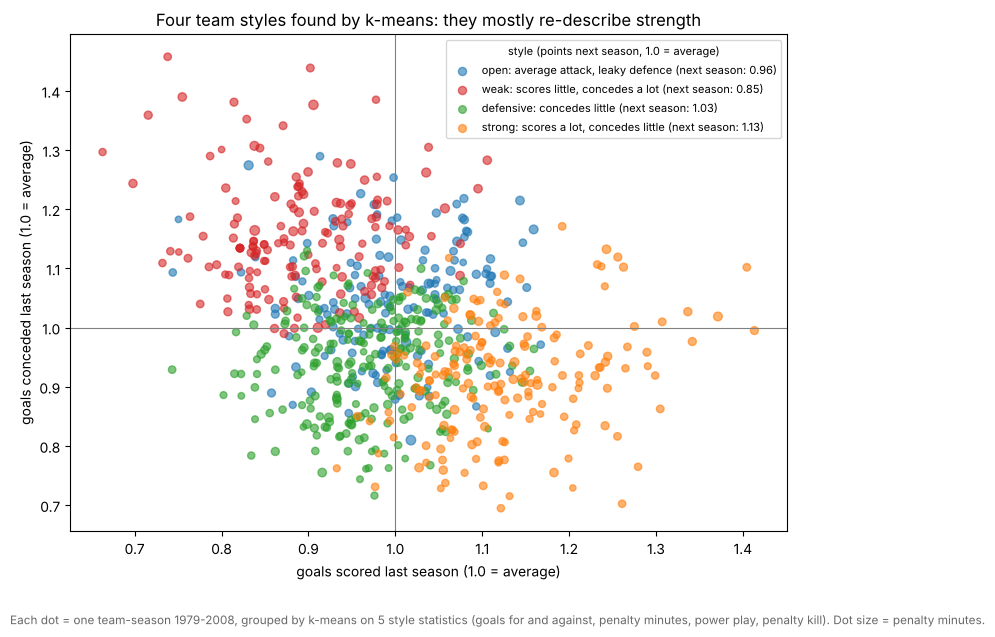

,last_gf_vs_avg,last_ga_vs_avg,last_pim_vs_avg,last_pp_pct,last_pk_pct,teams,points next season (vs avg)
style,,,,,,,
0,1.00,1.04,1.03,0.22,0.77,150,0.96
1,0.89,1.16,1.05,0.16,0.80,157,0.85
2,0.97,0.94,0.96,0.16,0.84,238,1.03
3,1.13,0.92,0.97,0.22,0.83,178,1.13


In [5]:
def with_style_clusters(k):
    def predict(train, test):
        scaler = StandardScaler().fit(train[STYLE])
        km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(scaler.transform(train[STYLE]))
        def inputs(df):
            groups = np.eye(k)[km.predict(scaler.transform(df[STYLE]))][:, 1:]    # one 0/1 column per group (minus one)
            return np.hstack([df[F3].values, groups])
        model = LinearRegression().fit(inputs(train), train["pts_vs_avg"])
        return conference_rank(test, model.predict(inputs(test)))
    return predict

cluster_candidates = {f"k = {k}": with_style_clusters(k) for k in [3, 4, 6]}
chosen_k = []
def clusters_fair(train, test):
    best, _ = pick_with_practice_test(train, cluster_candidates, err_a)
    chosen_k.append(best)
    return cluster_candidates[best](train, test)
results_a["Linear + style clusters (k by practice test)"] = evaluate_by_season(conf_table, clusters_fair, err_a, seasons)["score"]
print("k chosen per test season:", chosen_k)

# What the groups look like (k = 4, fitted on all seasons before 2009), in hockey terms
train_all = conf_table[conf_table["year"] < 2009]
scaler = StandardScaler().fit(train_all[STYLE])
km = KMeans(n_clusters=4, n_init=10, random_state=0).fit(scaler.transform(train_all[STYLE]))
styles = train_all.assign(style=km.labels_)
profile = styles.groupby("style")[STYLE + ["pts_vs_avg"]].mean().round(2)
profile["teams"] = styles["style"].value_counts().sort_index()
profile["points next season (vs avg)"] = profile.pop("pts_vs_avg")
def style_name(row):
    if row["last_gf_vs_avg"] > 1.05 and row["last_ga_vs_avg"] < 0.95: return "strong: scores a lot, concedes little"
    if row["last_gf_vs_avg"] < 0.95 and row["last_ga_vs_avg"] > 1.05: return "weak: scores little, concedes a lot"
    if row["last_ga_vs_avg"] < 0.97: return "defensive: concedes little"
    return "open: average attack, leaky defence"
names = profile.apply(style_name, axis=1)
fig, ax = plt.subplots(figsize=(8, 6))
for k, colour in zip(profile.index, ["tab:blue", "tab:red", "tab:green", "tab:orange"]):
    g = styles[styles["style"] == k]
    ax.scatter(g["last_gf_vs_avg"], g["last_ga_vs_avg"], s=g["last_pim_vs_avg"] * 30, color=colour, alpha=0.6,
               label=f"{names[k]} (next season: {profile.loc[k, 'points next season (vs avg)']:.2f})")
ax.axvline(1, color="grey", lw=0.8); ax.axhline(1, color="grey", lw=0.8)
ax.set(xlabel="goals scored last season (1.0 = average)", ylabel="goals conceded last season (1.0 = average)",
       title="Four team styles found by k-means: they mostly re-describe strength")
ax.legend(fontsize=8, loc="upper right", title="style (points next season, 1.0 = average)", title_fontsize=8)
footnote(fig, "Each dot = one team-season 1979-2008, grouped by k-means on 5 style statistics (goals for and against, penalty minutes, power play, penalty kill). Dot size = penalty minutes.")
plt.tight_layout(); plt.savefig(FIG / "team_styles.png", dpi=150, bbox_inches="tight"); plt.show()
profile

## A4. Recent seasons count more (time weighting)

**Idea.** In the season-by-season test the model learns from every season since 1979 with equal weight. But the game changes (rules, number of teams, scoring). Giving each training season a weight of `decay ^ (years ago)` makes recent seasons count more: with decay 0.9, a season 10 years ago counts 0.9¹⁰ ≈ 0.35 as much as last season. This is the idea behind data streams / online learning, where models adapt to the newest data.

The decay (1 = all equal, 0.95, 0.9 or 0.8) is chosen by the practice test.

In [6]:
def recency_linear(decay):
    def predict(train, test):
        w = decay ** (train["year"].max() - train["year"])
        model = LinearRegression().fit(train[F3], train["pts_vs_avg"], sample_weight=w)
        return conference_rank(test, model.predict(test[F3]))
    return predict

decay_candidates_a = {f"decay {d}": recency_linear(d) for d in [1.0, 0.95, 0.9, 0.8]}
chosen_decay_a = []
def recency_fair_a(train, test):
    best, _ = pick_with_practice_test(train, decay_candidates_a, err_a)
    chosen_decay_a.append(best)
    return decay_candidates_a[best](train, test)
results_a["Linear, recent seasons weighted (decay by practice test)"] = evaluate_by_season(conf_table, recency_fair_a, err_a, seasons)["score"]
print("Decay chosen per test season:", chosen_decay_a)
compare({"Linear, recent seasons weighted (decay by practice test)": results_a["Linear, recent seasons weighted (decay by practice test)"]},
        rule_a, best_a, "rule", "best model")

Decay chosen per test season: ['decay 0.8', 'decay 0.8', 'decay 1.0', 'decay 1.0', 'decay 1.0', 'decay 1.0', 'decay 1.0', 'decay 1.0', 'decay 0.8']


,score,better than rule,Wilcoxon p vs rule,better than best model,Wilcoxon p vs best model
"Linear, recent seasons weighted (decay by practice test)",3.2,3 / 9,0.516,0 / 9,0.25


## Task (a): all approaches together

Positions off in the conference (lower is better), against the Pythagorean rule (3.16) and our best model so far (3.16).

In [7]:
compare(results_a, rule_a, best_a, "rule", "best model").sort_values("score")

,score,better than rule,Wilcoxon p vs rule,better than best model,Wilcoxon p vs best model
Voting (linear + kNN + boosting),3.13,5 / 9,0.574,4 / 9,0.625
"Pairwise, 3 inputs",3.19,4 / 9,0.668,3 / 9,0.797
"Pairwise, 5 inputs",3.19,4 / 9,0.93,4 / 9,0.719
"Linear, recent seasons weighted (decay by practice test)",3.2,3 / 9,0.516,0 / 9,0.25
Linear + style clusters (k by practice test),3.24,3 / 9,0.086,1 / 9,0.094


### What the approaches show for (a)

| Approach | Positions off | What we learn |
|---|---|---|
| Voting ensemble | 3.13 | The lowest number, but better than the Pythagorean rule in only 5 of 9 seasons (p = 0.57): the three models make mostly the **same** mistakes, so averaging them cancels little |
| Pairwise ranking | 3.19 | Learning the order directly gives the same result as learning points. Its weights read like hockey: the 3-season average counts most (0.48), then last season's points (0.39), goal difference (0.24) and the players (0.22); goalies who conceded more lower the chance (−0.27) |
| Recent seasons weighted | 3.20 | The practice test chose "all seasons equal" in 6 of 9 seasons: old seasons do not hurt, because every value is already compared with its season's average |
| Style clusters as an input | 3.24 | The practice test switched between 3 and 6 groups and the result got slightly worse (p = 0.09 vs the best model). Style does not add information beyond goals and points |

**The style groups themselves are a useful finding** (`figures/team_styles.png`, 4 groups): the strongest group next season (1.13 of the average) scores a lot *and* concedes little with good special teams; a "defensive" group (scores below average, 0.97, but concedes little, 0.94, and has the best penalty kill, 0.84) stays above average (1.03); the weakest group (0.85) scores little, concedes a lot and takes the most penalties. So style mostly **re-describes strength**, which explains why it adds nothing as an input.

**Overall for (a):** five very different approaches (regression, pairwise classification, ensemble, clustering, time weighting) all land at 3.13–3.24 positions off, none proven better than the Pythagorean rule. When methods this different agree, the limit is the **information available before the season**, not the method. That is the conclusion for (a).

## Task (c): data

The player table from notebook 04, with the same 20 inputs. Baseline: **Marcel** (17.17). Best model so far: **gradient boosting with absolute error** (16.53).

In [8]:
F_C = ["PIM_1", "PIM_2", "PIM_3", "GP_1", "GP_2", "GP_3", "rate_1", "career_rate", "marcel_rate_vs_league",
       "games_guess", "pts_rate_1", "seasons_before", "first_season", "pos_C", "pos_D", "pos_L", "pos_R", "pos_G",
       "team_style_last", "league_rate_last"]

def boosting(loss="absolute_error"):
    return HistGradientBoostingRegressor(loss=loss, learning_rate=0.05, max_leaf_nodes=7, max_iter=300, min_samples_leaf=40, random_state=0)

def marcel(train, test):
    firsts = train[train["first_season"] == 1]
    fill = test["pos"].map(firsts.groupby("pos")["PIM"].median()).fillna(firsts["PIM"].median())
    return (test["marcel_rate_vs_league"] * test["league_rate_last"] * test["games_guess"]).where(test["first_season"] == 0, fill).values

rule_c = evaluate_by_season(player_table, marcel, pim_mae, seasons)["score"]
best_c = evaluate_by_season(player_table, lambda tr, te: np.clip(boosting().fit(tr[F_C], tr["PIM"]).predict(te[F_C]), 0, None), pim_mae, seasons)["score"]
print("Marcel:", round(rule_c.mean(), 2), "| best model so far:", round(best_c.mean(), 2))

Marcel: 17.17 | best model so far: 16.53


## C1. Rate × games (two regressions)

**Idea.** Total PIM = (penalty minutes per game) × (games played). We already know games played is the biggest unknown (notebook 04: with the real games the error would be 14.0). So we split the problem:
1. **Rate model:** gradient boosting predicts PIM per game, trained on players who played, each weighted by his games (a rate from 80 games is more reliable than one from 2).
2. **Games model:** gradient boosting predicts games played this season.
3. Prediction = rate × games.

**Why:** each part is simpler and can be explained on its own, and we can see **which part** causes the error.

In [9]:
def rate_times_games(train, test, return_parts=False):
    played = train[train["GP"] > 0]
    rate = boosting("squared_error").fit(played[F_C], played["PIM"] / played["GP"], sample_weight=played["GP"])
    games = boosting().fit(train[F_C], train["GP"])
    r, g = np.clip(rate.predict(test[F_C]), 0, None), np.clip(games.predict(test[F_C]), 0, 82)
    return (r, g) if return_parts else r * g

results_c = {"Rate × games": evaluate_by_season(player_table, rate_times_games, pim_mae, seasons)["score"]}

# How good is each part? Games model error, and the rate model with the REAL games (not allowed, only to locate the error)
games_err = evaluate_by_season(player_table, lambda tr, te: rate_times_games(tr, te, True)[1],
                               lambda te, p: np.mean(np.abs(te["GP"] - p)), seasons)["score"]
rate_real_games = evaluate_by_season(player_table, lambda tr, te: rate_times_games(tr, te, True)[0] * te["GP"].values, pim_mae, seasons)["score"]
print("Games model: on average", round(games_err.mean(), 1), "games off (a season has 80-82)")
print("Rate model × REAL games (not allowed):", round(rate_real_games.mean(), 2), "minutes off")
compare({"Rate × games": results_c["Rate × games"]}, rule_c, best_c, "Marcel", "best model")

Games model: on average 15.7 games off (a season has 80-82)
Rate model × REAL games (not allowed): 12.03 minutes off


,score,better than Marcel,Wilcoxon p vs Marcel,better than best model,Wilcoxon p vs best model
Rate × games,17.57,4 / 9,0.82,1 / 9,0.027


## C2. Two-step model: any penalties at all? Then how many?

**Idea.** 12% of player-seasons have 0 PIM. A two-step model (a "hurdle" model):
1. **Classifier** (gradient boosting, T03): will the player get any penalty minutes?
2. **Regressor** (gradient boosting with absolute error, T02), trained only on players with PIM > 0: how many?
3. If the classifier says "yes" (chance ≥ 0.5), predict the regressor's number; otherwise predict 0.

**Why:** zero is a special case (players who barely play, goalies), and a single regressor has to treat it like any other number.

In [10]:
def two_step(train, test):
    clf = HistGradientBoostingClassifier(learning_rate=0.05, max_leaf_nodes=7, max_iter=300, min_samples_leaf=40, random_state=0)
    clf.fit(train[F_C], (train["PIM"] > 0).astype(int))
    some = train[train["PIM"] > 0]
    reg = boosting().fit(some[F_C], some["PIM"])
    any_pim = clf.predict_proba(test[F_C])[:, 1] >= 0.5
    return np.where(any_pim, np.clip(reg.predict(test[F_C]), 0, None), 0)

results_c["Two-step (any PIM? then how many)"] = evaluate_by_season(player_table, two_step, pim_mae, seasons)["score"]
compare({"Two-step (any PIM? then how many)": results_c["Two-step (any PIM? then how many)"]}, rule_c, best_c, "Marcel", "best model")

,score,better than Marcel,Wilcoxon p vs Marcel,better than best model,Wilcoxon p vs best model
Two-step (any PIM? then how many),16.9,8 / 9,0.008,1 / 9,0.008


## C3. Stacking: learn how much to trust each model

**Idea.** Four models (linear, decision tree depth 6, k-nearest neighbours k = 100, gradient boosting) each make a prediction. A second step learns **weights** for them: how much each one should count in the final answer (T05).

**Correct setup, respecting time:** the weights are learned on the **practice seasons** (last 3 training seasons), with the four models trained on the seasons before them; then the four models are retrained on all training seasons and combined with those weights. Weights are not negative (a model cannot count "less than nothing").

In [11]:
stack_members = {
    "linear": (lambda: make_pipeline(StandardScaler(), LinearRegression()), True),
    "tree": (lambda: DecisionTreeRegressor(max_depth=6, min_samples_leaf=50, random_state=0), True),
    "kNN": (lambda: make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=100)), True),
    "boosting": (boosting, False),
}
def member_predictions(train, test):
    cols = []
    for make, fill in stack_members.values():
        Xtr, Xte = (train[F_C].fillna(-1), test[F_C].fillna(-1)) if fill else (train[F_C], test[F_C])
        cols.append(np.clip(make().fit(Xtr, train["PIM"]).predict(Xte), 0, None))
    return np.column_stack(cols)

stack_weights = []
def stacking(train, test):
    practice = sorted(train["year"].unique())[-3:]
    inner, prac = train[train["year"] < practice[0]], train[train["year"].isin(practice)]
    w, _ = nnls(member_predictions(inner, prac), prac["PIM"].values.astype(float))     # non-negative weights
    stack_weights.append(w)
    return member_predictions(train, test) @ w

results_c["Stacking (weights from practice seasons)"] = evaluate_by_season(player_table, stacking, pim_mae, seasons)["score"]
print("Weights per test season (linear, tree, kNN, boosting):")
print(pd.DataFrame(stack_weights, columns=list(stack_members), index=seasons).round(2))
compare({"Stacking (weights from practice seasons)": results_c["Stacking (weights from practice seasons)"]}, rule_c, best_c, "Marcel", "best model")

Weights per test season (linear, tree, kNN, boosting):
      linear  tree   kNN  boosting
2000    0.39  0.14  0.04      0.35
2001    0.35  0.07  0.17      0.30
2002    0.57  0.00  0.14      0.22
2003    0.40  0.00  0.19      0.42
2005    0.45  0.09  0.09      0.35
2006    0.12  0.14  0.39      0.33
2007    0.09  0.09  0.43      0.39
2008    0.03  0.19  0.52      0.25
2009    0.46  0.08  0.11      0.31


,score,better than Marcel,Wilcoxon p vs Marcel,better than best model,Wilcoxon p vs best model
Stacking (weights from practice seasons),17.04,7 / 9,0.129,0 / 9,0.004


## C4. Recent seasons count more (time weighting)

Same idea as A4, for gradient boosting with absolute error: each training season is weighted `decay ^ (years ago)`, and the practice test chooses the decay (1 = all equal, 0.95 or 0.9). This cell takes a few minutes.

In [12]:
def recency_boosting(decay):
    def predict(train, test):
        w = decay ** (train["year"].max() - train["year"])
        return np.clip(boosting().fit(train[F_C], train["PIM"], sample_weight=w).predict(test[F_C]), 0, None)
    return predict

decay_candidates_c = {f"decay {d}": recency_boosting(d) for d in [1.0, 0.95, 0.9]}
chosen_decay_c = []
def recency_fair_c(train, test):
    best, _ = pick_with_practice_test(train, decay_candidates_c, pim_mae)
    chosen_decay_c.append(best)
    return decay_candidates_c[best](train, test)
results_c["Boosting, recent seasons weighted (decay by practice test)"] = evaluate_by_season(player_table, recency_fair_c, pim_mae, seasons)["score"]
print("Decay chosen per test season:", chosen_decay_c)
compare({"Boosting, recent seasons weighted (decay by practice test)": results_c["Boosting, recent seasons weighted (decay by practice test)"]},
        rule_c, best_c, "Marcel", "best model")

Decay chosen per test season: ['decay 1.0', 'decay 1.0', 'decay 0.9', 'decay 0.95', 'decay 1.0', 'decay 1.0', 'decay 1.0', 'decay 0.95', 'decay 1.0']


,score,better than Marcel,Wilcoxon p vs Marcel,better than best model,Wilcoxon p vs best model
"Boosting, recent seasons weighted (decay by practice test)",16.56,9 / 9,0.004,3 / 9,0.164


## Task (c): all approaches together

Minutes off per player (lower is better), against Marcel (17.17) and our best model so far (16.53).

In [13]:
compare(results_c, rule_c, best_c, "Marcel", "best model").sort_values("score")

,score,better than Marcel,Wilcoxon p vs Marcel,better than best model,Wilcoxon p vs best model
"Boosting, recent seasons weighted (decay by practice test)",16.56,9 / 9,0.004,3 / 9,0.164
Two-step (any PIM? then how many),16.9,8 / 9,0.008,1 / 9,0.008
Stacking (weights from practice seasons),17.04,7 / 9,0.129,0 / 9,0.004
Rate × games,17.57,4 / 9,0.82,1 / 9,0.027


### What the approaches show for (c)

| Approach | Minutes off | What we learn |
|---|---|---|
| Boosting, recent seasons weighted | 16.56 | Same as plain boosting (16.53, p = 0.16); the practice test mostly chose "all seasons equal" (6 of 9): old seasons do not hurt, because history is compared with the league rate |
| Two-step (any PIM? then how many) | 16.90 | Better than Marcel (8/9, p = 0.008) but worse than plain boosting (p = 0.008): when the classifier wrongly says "0", the whole season is missed; boosting with absolute error already predicts close to 0 for those players |
| Stacking | 17.04 | Worse than boosting alone in all 9 seasons (p = 0.004). The weights are learned by reducing the **squared** error, so they favour the linear model, which chases the enforcers; and they change a lot from season to season (linear 0.03–0.57): 3 practice seasons are too few to learn stable weights |
| Rate × games | 17.57 | The worst, but the most informative: the **games** model is 15.7 games off on average, and with the real games the rate model would be 12.0 minutes off. So the rate per game is predictable; **games played is the problem** (injuries, being sent down), and multiplying two uncertain guesses adds their errors |

**Overall for (c):** splitting the problem (rate × games, two-step) and combining models (stacking) did not beat one gradient boosting model trained on the right error (absolute). But rate × games **located the error**: almost all of what we cannot predict is how many games a player will play.